# Tutorial 13 — Relaxation spectrum

The linear viscoelastic response of a material is fully characterised by its
**relaxation spectrum**: the distribution of relaxation strengths over
relaxation times $s$. In the continuous form, with $h(s)$ in Pa and
$H(s)=\ln h(s)$,

$$G(t)=G_e+\int_{-\infty}^{\infty} h(s)\,e^{-t/s}\,d\ln s,$$

$$G'(\omega)=G_e+\int_{-\infty}^{\infty}\frac{\omega^2 s^2}{1+\omega^2 s^2}\,h(s)\,d\ln s,\qquad
G''(\omega)=\int_{-\infty}^{\infty}\frac{\omega s}{1+\omega^2 s^2}\,h(s)\,d\ln s,$$

where $G_e$ is the equilibrium (plateau) modulus, zero for liquids
(`plateau=False`). The discrete counterpart is a Prony series of Maxwell modes,

$$G(t)=G_e+\sum_{i=1}^{N} g_i\,e^{-t/\tau_i}.$$

Recovering $h(s)$ from $G(t)$ or $G^*(\omega)$ is an ill-posed inverse problem
(a Fredholm integral equation of the first kind): small noise in the data
produces large oscillations in the spectrum. `RelaxationSpectrum` wraps the
vendored pyReSpect solvers by Shanbhag [1–3], which proceed in two steps:

1. **Continuous spectrum.** $H(s)$ is found by nonlinear Tikhonov
   regularisation, minimising
   $\lVert \mathbf{G}_{\text{data}}-\mathbf{K}\,e^{\mathbf{H}}\rVert^2+\lambda\,\lVert \mathbf{L}\mathbf{H}\rVert^2$,
   where $\mathbf{K}$ is the kernel above and $\mathbf{L}$ a second-derivative
   operator penalising roughness. Fitting $H=\ln h$ keeps $h>0$. The
   regularisation parameter $\lambda$ is selected by a Bayesian criterion [2];
   `lam_C` fixes it, and `SmFacLam` biases it toward smoother or sharper spectra.
2. **Discrete spectrum.** Mode positions $\tau_i$ are seeded from the
   continuous spectrum, the amplitudes $g_i$ are fitted by nonlinear least
   squares, and the number of modes $N$ is chosen by minimising the Akaike
   information criterion (AIC), which balances fit quality and parsimony.

`domain="time"` takes $G(t)$; `domain="frequency"` takes $G'(\omega)$ and
$G''(\omega)$. Inputs must be in SI units (s, rad/s, Pa). The transform
prepends two datasets to the measurement (continuous and discrete spectrum) and
stores the full solver output in `details["relaxation_spectrum_result"]`.

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from hermes_rheo.lve_models import MaxwellModel, Protocols
from hermes_rheo.transforms import RelaxationSpectrum
from hermes_rheo.visualization import plot_relaxation_spectrum, use_science_style

use_science_style()
warnings.filterwarnings("ignore")  # master-curve optimiser convergence notices
DATA = Path("tutorial_data")

## Validation: single-mode Maxwell model

A Maxwell element, $G(t)=G_0\,e^{-t/\tau}$ with $G_0=10^5$ Pa and
$\tau=1$ s, has a delta-function spectrum $h(s)=G_0\,\delta(\ln s-\ln\tau)$.
The discrete spectrum should therefore return exactly one mode at
$(\tau, g)=(1\ \text{s}, 10^5\ \text{Pa})$. The input here is the relaxation
modulus $G(t)$ over five decades in time.

In [2]:
G0, tau = 1e5, 1.0
relax = Protocols.stress_relaxation(MaxwellModel(G=G0, tau=tau), np.geomspace(1e-3, 1e2, 100))
rs = RelaxationSpectrum(domain="time", relaxation_name="relaxation modulus")
rs(relax)
r = rs.result
print("discrete modes:", len(r.tau), "| tau (s):", np.round(r.tau, 3), "| g (Pa):", np.round(r.g, 0))

discrete modes: 1 | tau (s): [+1.0000] | g (Pa): [+100000.0000]


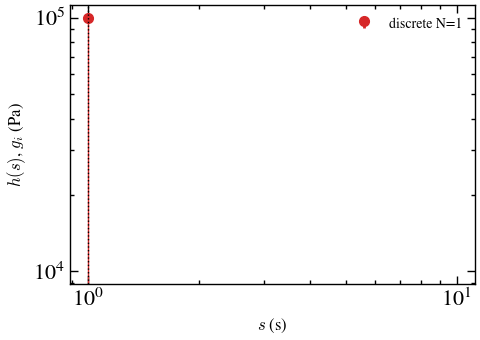

In [3]:
fig, ax = plt.subplots(figsize=(5, 3.6))
plot_relaxation_spectrum(r, ax=ax, show_continuous=False)
ax.axvline(tau, color="k", ls=":", lw=1); plt.show()

The AIC selects a single mode at the true values (dotted line: true
$\tau$). The continuous spectrum of a delta function is necessarily broadened by
the regularisation and is not shown.

## Experimental data: polymer master curve

A single frequency sweep covers only a few decades, which limits the range of
$s$ that can be resolved: roughly $1/\omega_{\max}\lesssim s\lesssim 1/\omega_{\min}$.
Time–temperature superposition extends this window. The isothermal sweeps from
Tutorial 4 are shifted onto a master curve at the reference temperature with
`CompositeMasterCurve` (Lennon et al. [4]), and the spectrum is extracted from
the shifted $G'(\omega)$ and $G''(\omega)$.

In [4]:
from piblin.data import Measurement, OneDimensionalCompositeDataset
from hermes_rheo import read_file
from hermes_rheo.file_readers.trios_rheo_txt import TriosRheoReader
from hermes_rheo.transforms import CompositeMasterCurve

exp = read_file(DATA / "aresg2_trios_frequency_sweep_tts.txt",
                file_reader=TriosRheoReader, create_composite_datasets=True)
mc = CompositeMasterCurve(n_curves=2, y_quantities=["storage modulus", "loss modulus"],
                          x="angular frequency", state="temperature", state_mode="average",
                          vertical_shift=False, sort_states=True, ref_temp_idx=6)(exp)
w, gp = mc.get_mastercurve("storage modulus").datasets[0].data_arrays[:2]
wb, gpp = mc.get_mastercurve("loss modulus").datasets[0].data_arrays[:2]
gpp = np.exp(np.interp(np.log(w), np.log(wb), np.log(gpp)))  # common frequency grid
master = Measurement(datasets=[OneDimensionalCompositeDataset(
    data_arrays=[w, gp * 1e6, gpp * 1e6],  # MPa -> Pa
    data_array_names=["angular frequency", "storage modulus", "loss modulus"],
    data_array_units=["rad/s", "Pa", "Pa"],
    default_independent_name="angular frequency", default_dependent_name="storage modulus")])
print(f"{len(w)} points, {w.min():.1e}-{w.max():.1e} rad/s")

340 points, 1.4e-05-1.1e+10 rad/s


In [5]:
rs = RelaxationSpectrum(domain="frequency")
rs(master)
r = rs.result
print("optimal discrete modes:", len(r.tau))

optimal discrete modes: 18


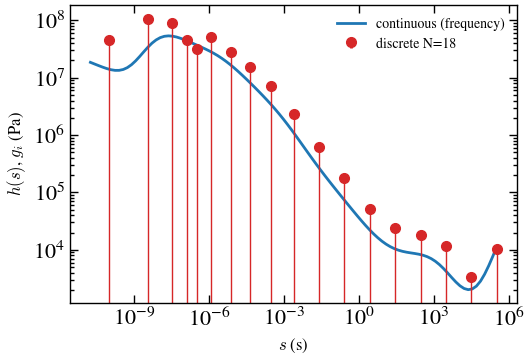

In [6]:
fig, ax = plt.subplots(figsize=(5.5, 3.8))
plot_relaxation_spectrum(r, ax=ax, show_uncertainty=False)
plt.show()

$h(s)$ decreases from the glassy modes ($s\sim10^{-9}$–$10^{-6}$ s, $h\sim10^{7}$–$10^{8}$ Pa)
through the glass transition to the low-modulus long-time region. The AIC
selects 18 discrete modes, roughly one per decade, which is the expected
resolution limit for an inversion of this kind. The discrete modes give a
compact Maxwell representation that can be used to compute any other linear
response (creep compliance, start-up of shear, etc.). The features at both ends
of the $s$ axis, including the upturn at the longest times, lie outside the
data window $1/\omega_{\max}\lesssim s\lesssim 1/\omega_{\min}$ and should not
be interpreted physically.

## References

1. Shanbhag, S., *pyReSpect: A computer program to extract discrete and continuous spectra from stress relaxation experiments*, Macromol. Theory Simul. **28**, 1900005 (2019). doi:[10.1002/mats.201900005](https://doi.org/10.1002/mats.201900005).
2. Shanbhag, S., *Relaxation spectra using nonlinear Tikhonov regularization with a Bayesian criterion*, Rheol. Acta **59**, 509–520 (2020). doi:[10.1007/s00397-020-01212-w](https://doi.org/10.1007/s00397-020-01212-w).
3. Takeh, A. & Shanbhag, S., *A computer program to extract the continuous and discrete relaxation spectra from dynamic viscoelastic measurements*, Appl. Rheol. **23**, 24628 (2013). doi:[10.3933/applrheol-23-24628](https://doi.org/10.3933/applrheol-23-24628).
4. Lennon, K. R., McKinley, G. H. & Swan, J. W., *A data-driven method for automated data superposition with applications in soft matter science*, Data-Centric Eng. **4**, e13 (2023). doi:[10.1017/dce.2023.3](https://doi.org/10.1017/dce.2023.3).
5. Ferry, J. D., *Viscoelastic Properties of Polymers*, 3rd ed., Wiley (1980).